# Solar filament segmentation: end-to-end notebook

This notebook reproduces our final submissions to the Solar Filament Segmentation Challenge 2026 from the
competition data:

1. **Data and preprocessing**: ground truth per annotator record, soft training targets, day-grouped folds, network input normalisation.
2. **Models**: download the released weights (default) **or** train every model from scratch (`TRAIN_FROM_SCRATCH`),
   plus a short training run of one model that shows the training code at work (`TRAIN_DEMO`).
3. **Inference and post-processing** on the 180 test frames: dense U-Net ensemble -> candidate filaments ->
   LightGBM scorer -> crop refiner -> CNN rescorer -> selection -> pixel-disjoint masks -> submission CSV.
4. **Evaluation**: 5-fold out-of-fold (OOF) predictions on the 707 labelled training frames, scored with the metrics of
   the host's self-evaluation notebook (pooled PQ, IoU / Dice distributions, one-to-many / many-to-one matching).
5. **Predicted filaments** on test frames.

All code is in the `filseg` package of this repository; every cell names the module it calls. The weights are
downloaded automatically from Hugging Face ([NightNightUp/filament-segmentation-2026](https://huggingface.co/NightNightUp/filament-segmentation-2026)).

| run | pick s15 | pick s16 |
|---|---|---|
| default (download weights, 2-epoch training demo, inference, evaluation) | 6.8 GB download; 27 min on two H100s (inference 21 min), about 45 min on one GPU | 2.5 GB download; about 15 min on one H200 |
| `RECOMPUTE_OOF = True` (OOF predictions from the weights instead of `final/oof_<pick>.csv`) | + about 1.5 h on one GPU | + about 1 h |
| `TRAIN_FROM_SCRATCH = True` (every model of s15 and s16) | about 70 H200-hours | same run |

Setup: `pip install -r requirements.txt` (Python 3.11, CUDA GPU), then run the notebook from the repository root.
The executed copy below ran with the defaults for s15 on two H100 GPUs, starting from an empty folder (the weights
were downloaded by the notebook).

In [1]:
import json, os, subprocess, sys, time, warnings
import numpy as np
warnings.filterwarnings("ignore", message="IProgress not found")  # tqdm without ipywidgets

def flag(name, default):  # every switch can also be set from the environment, e.g. TRAIN_FROM_SCRATCH=1
    return os.environ.get(name, str(int(default))) == "1"

PICK = os.environ.get("PICK", "s15")                   # "s15" (teacher ensemble) or "s16" (distilled students)
TRAIN_FROM_SCRATCH = flag("TRAIN_FROM_SCRATCH", False)  # True: retrain every model (~70 H200-hours) instead of downloading the weights
TRAIN_DEMO = flag("TRAIN_DEMO", True)                   # train one U-Net for 2 epochs on folds 1-4 (~3 min) to show the training code
RECOMPUTE_OOF = flag("RECOMPUTE_OOF", False)            # True: recompute the 5-fold OOF predictions from the weights (GPU-hours)
HF_REPO = "NightNightUp/filament-segmentation-2026"     # Hugging Face repo with the released weights

os.environ.setdefault("FIL_DATA", "data")               # folder with train/ and test/ as downloaded from Kaggle
os.environ.setdefault("FIL_WEIGHTS", "weights")         # the released weights are downloaded here
os.environ.setdefault("FIL_WORK", "work_demo")          # everything the pipeline writes
SUBMITTED = os.environ.get("SUBMITTED", "")             # optional: the CSV we submitted to Kaggle, for comparison
OUT = f"submission_{PICK}.csv"

def run(cmd, env=None):
    # runs a command of this repository and streams its output into the notebook
    p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
                         env=dict(os.environ, PYTHONUNBUFFERED="1", **(env or {})))
    for line in p.stdout:
        print(line, end="", flush=True)
    assert p.wait() == 0, f"failed ({p.returncode}): {' '.join(cmd)}"

import torch
GPUS = list(range(torch.cuda.device_count()))
assert GPUS, "a CUDA GPU is needed"
from filseg.paths import P
cfg = json.load(open(f"final/{PICK}.json"))
cfg["_pool"] = json.load(open("final/pool.json"))       # candidate sets of the rescorer training pool (OOF only)
print(cfg["summary"])
print(f"data: {P.data} | weights: {P.weights} | work: {P.work}")
print("GPUs:", [torch.cuda.get_device_name(g) for g in GPUS])

teacher ensemble ensB -> LightGBM scorer -> crop refiner (0.5) -> score = mean(LGB, mean of 3 CNN rescorers) > 0.22
data: data | weights: weights | work: work_demo
GPUs: ['NVIDIA H100 80GB HBM3', 'NVIDIA H100 80GB HBM3']


## 1. Data and preprocessing

The competition data (`train/train_images/*.jpeg`, `train/MAGFiLO_1.0_Annotations_kaggle2026_train.json`,
`test/test_images/*.jpeg`) is downloaded with the Kaggle API if it is not already in `FIL_DATA`.

In [2]:
from filseg.common import list_stems
if not (os.path.exists(P.train_json) and os.path.isdir(P.images)):
    # needs the Kaggle API (pip install kaggle, ~/.kaggle/kaggle.json) and the competition rules accepted on kaggle.com
    os.makedirs(P.data, exist_ok=True)
    run(["kaggle", "competitions", "download", "-c", "filament-segmentation-2026", "-p", P.data])
    run(["unzip", "-q", "-o", os.path.join(P.data, "filament-segmentation-2026.zip"), "-d", P.data])
print(f"{len(list_stems(P.train_images))} training frames, {len(list_stems(P.images))} test frames (2048 x 2048, grayscale)")

707 training frames, 180 test frames (2048 x 2048, grayscale)


`filseg.prep` parses the COCO annotations. Several annotators labelled most frames, and the metric treats every
annotator record as its own ground-truth set, so the ground truth is kept per record (`cache/gt.pkl`). The training
target of the dense models is the **mean of the records' filament masks** (a soft target in [0, 1]). The 5 folds
group frames by observation day (frames of one day from different GONG sites show the same filaments).

In [3]:
from collections import Counter
from filseg.common import load_gt, load_meta
if not os.path.exists(os.path.join(P.cache, "meta.json")):
    run([sys.executable, "-m", "filseg.prep"])
meta, gt = load_meta(), load_gt()
print("frames per fold:", dict(sorted(Counter(meta["folds"].values()).items())))
print("annotator records per frame:", dict(sorted(Counter(len(g) for g in gt.values()).items())))
print("filament instances over all records:", sum(len(r) for g in gt.values() for r in g))

images 707 test 180 fold sizes Counter({1: 145, 3: 144, 0: 143, 4: 138, 2: 137})


annotator records 1154 instances/record mean 7.104852686308492 median 7.0


instance area percentiles 1/5/10/25/50/75/90/99: [  208.98   316.9    409.8    670.    1228.    2438.    4684.6  13703.44]


frames per fold: {0: 143, 1: 145, 2: 137, 3: 144, 4: 138}
annotator records per frame: {1: 411, 2: 145, 3: 151}
filament instances over all records: 8199


What the networks see: the 8-bit frame is normalised per frame, either a z-score over the solar disk (`norm z`) or a
flat-field contrast map that divides out limb darkening and large-scale background such as clouds (`norm flat`).

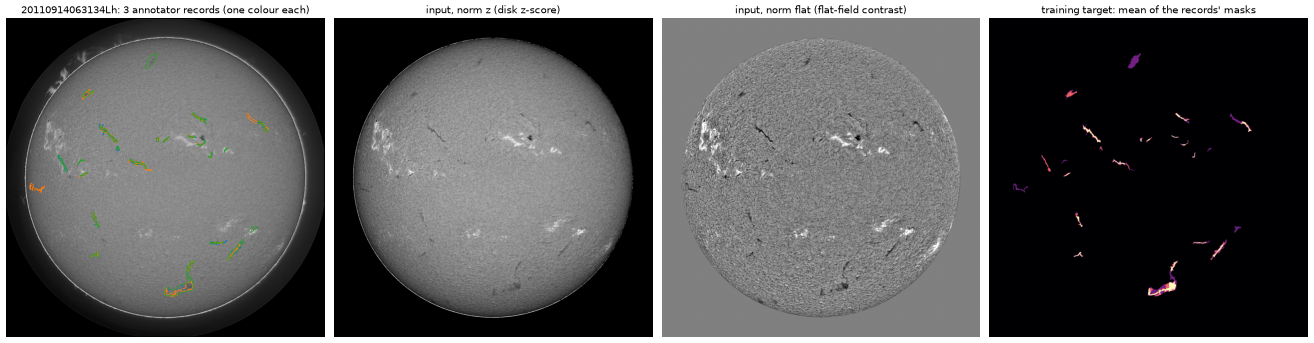

In [4]:
import cv2
import matplotlib.pyplot as plt
from pycocotools import mask as mu
from filseg.common import load_img, normalize
plt.rcParams["figure.dpi"] = 60
TAB = plt.cm.tab10.colors
records = lambda n: f"{n} annotator record" + ("s" if n != 1 else "")

stem = max(meta["stems"], key=lambda s: (len(gt[s]), sum(len(r) for r in gt[s])))
im = load_img(stem)
fig, ax = plt.subplots(1, 4, figsize=(22, 6))
ax[0].imshow(im, cmap="gray", vmin=0, vmax=255)
for i, rec in enumerate(gt[stem]):
    for r in rec:
        ax[0].contour(mu.decode(r), levels=[0.5], colors=[TAB[i % 10]], linewidths=0.8)
ax[0].set_title(f"{stem}: {records(len(gt[stem]))} (one colour each)")
ax[1].imshow(normalize(im, "z"), cmap="gray", vmin=-4, vmax=4); ax[1].set_title("input, norm z (disk z-score)")
ax[2].imshow(normalize(im, "flat"), cmap="gray", vmin=-4, vmax=4); ax[2].set_title("input, norm flat (flat-field contrast)")
ax[3].imshow(cv2.imread(os.path.join(P.cache, "targets", f"{stem}.png"), 0), cmap="magma", vmin=0, vmax=255)
ax[3].set_title("training target: mean of the records' masks")
for a in ax:
    a.axis("off")
plt.tight_layout(); plt.show()

## 2. Models: released weights or training from scratch

Each pick is described by `final/<pick>.json`:

* **dense models** (`filseg/train_dense.py`, `filseg/dense.py`): U-Nets with EfficientNetV2 encoders trained on the soft
  target (BCE + soft Dice, EMA weights, random 1024 or 1536 px crops, D4 / scale / photometric augmentation),
  5 fold models each. s16's students are distilled from the teachers on 1314 extra unlabelled GONG frames;
* **scorer** (`filseg/scorer.py`): LightGBM model of the expected IoU of a candidate filament;
* **refiner** (`filseg/refiner.py`): ResNet-34 U-Net that redraws each candidate's mask on a 192 px crop;
* **rescorers** (`filseg/rescorer.py`): ResNet-34 regressors of the candidate's expected IoU on the same crops.

By default the released weights are downloaded once from Hugging Face and every file is checked against
`final/weights_manifest.csv` (size and sha256); files already present are not downloaded again.
With `TRAIN_FROM_SCRATCH = True` the cell instead runs every stage of `scripts/train_from_scratch.sh`
(teachers, unlabelled frames, distillation, students, candidate pool, scorers, refiners, rescorers) and writes
the submission CSVs and OOF predictions of both picks into `FIL_WORK`; it takes about 70 H200-hours on one GPU.

In [5]:
if TRAIN_FROM_SCRATCH:
    run(["bash", "scripts/train_from_scratch.sh"])  # also writes submission_s15.csv, submission_s16.csv here
else:
    for bundle in ["inference"] + (["oof"] if RECOMPUTE_OOF else []):  # "oof": the fold refiners
        run([sys.executable, "scripts/get_weights.py", "--out", P.weights, "--hf_repo", HF_REPO, "--bundle", bundle,
             "--pick", PICK], env={"HF_HUB_DISABLE_PROGRESS_BARS": "1"})

downloading 102 files (6.80 GB) from NightNightUp/filament-segmentation-2026


102/102 files ok (6.80 GB) in weights


In [6]:
from filseg.candidates import parse_member
from filseg.dense import build
weight = dict(parse_member(m) for m in cfg["ensemble"])
src = P.runs if TRAIN_FROM_SCRATCH else os.path.join(P.weights, "dense")
print(f"{'map':26s} {'encoder':24s} {'crop':>5s} {'norm':>5s} {'epochs':>6s} {'unlabelled':>10s} {'TTA':>4s}  ensemble weight")
nparam = {}
for name, m in cfg["maps"].items():
    a = json.load(open(os.path.join(src, m["run"], "args_f0.json")))
    enc = a["encoder"]
    if enc not in nparam:
        nparam[enc] = sum(p.numel() for p in build(a.get("arch", "Unet"), enc).parameters()) / 1e6
    w = weight.get(name)
    print(f"{name:26s} {enc.split('.')[0].replace('tu-tf_', ''):24s} {a['crop']:5d} {a.get('norm', 'z'):>5s} {a['epochs']:6d} "
          f"{'yes' if a.get('pseudo') else '':>10s} {m['tta']:4d}  {w if w else 'extra rescorer channel only'}")
print("U-Net parameters:", {e.split('.')[0].replace('tu-tf_', ''): f"{n:.1f} M" for e, n in nparam.items()})
groups = cfg["rescorer"]["groups"]
sizes = ", ".join(f"{k}: {len(g['members'])}" for k, g in groups.items())
print(f"rescorers: {sum(len(g['members']) for g in groups.values())} networks in {len(groups)} groups ({sizes}); "
      f"score = {1 - cfg['rescorer']['w_cnn']:.1f} x LightGBM + {cfg['rescorer']['w_cnn']:.1f} x rescorers, keep if > {cfg['tau']}")

map                        encoder                   crop  norm epochs unlabelled  TTA  ensemble weight


e6_effv2s_c1536            efficientnetv2_s          1536     z     60               8  2.0


e10_effv2m_c1536           efficientnetv2_m          1536     z     60               8  2.0
e12_effv2s_flat_c1536      efficientnetv2_s          1536  flat     60               8  2.0
e1_tta8                    efficientnetv2_s          1024     z     60               8  1.0
e3_tta8                    efficientnetv2_s          1024  flat     60               8  1.0
e7_tta8                    efficientnetv2_m          1024     z     60               8  1.0
e31_kd_effv2s_c1536        efficientnetv2_s          1536     z     30        yes    8  extra rescorer channel only
e33_kd_effv2m_c1536        efficientnetv2_m          1536     z     30        yes    8  extra rescorer channel only
e34_kd_effv2s_flat_c1536   efficientnetv2_s          1536  flat     30        yes    8  extra rescorer channel only
U-Net parameters: {'efficientnetv2_s': '22.1 M', 'efficientnetv2_m': '55.1 M'}
rescorers: 8 networks in 3 groups (rsqE: 4, rso4: 2, rso6: 2); score = 0.5 x LightGBM + 0.5 x rescorers, keep if 

### Training demo

The full recipe of every model is in `scripts/train_from_scratch.sh` (per-run arguments are also stored next to each
checkpoint as `args_f<k>.json`). To show the training code at work without the full cost, this cell trains the
recipe of `e1` (EfficientNetV2-S U-Net, 1024 px crops) for 2 of its 60 epochs on folds 1-4 and predicts the
held-out fold 0. The quick validation PQ is a simple connected-component rule, not the full pipeline.

train 564 val 143


loaded in 40s


Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.


ep 0 loss 0.9693 lr 2.50e-04 21s


ep 1 loss 0.5581 lr 0.00e+00 19s


  val ep 1 quick PQ {'PQ': np.float64(0.3056674909344361), 'SQ': np.float64(0.6447069073031698), 'TP': 948, 'FP': 1489, 'FN': 614}


done 147.70405054092407


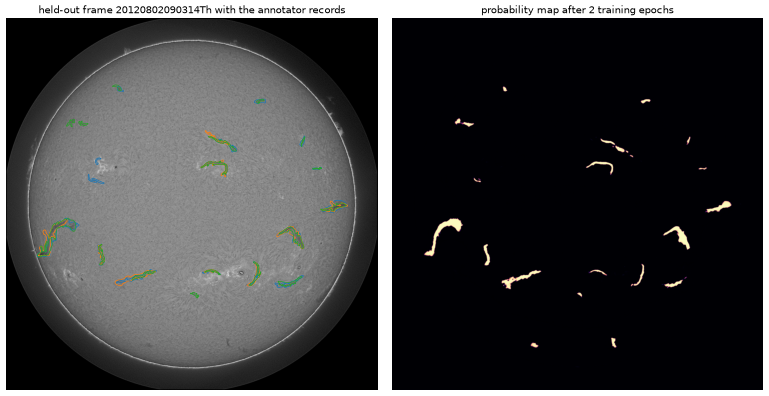

In [7]:
if TRAIN_DEMO:
    run([sys.executable, "-m", "filseg.train_dense", "--name", "demo_e1_2ep", "--fold", "0",
         "--encoder", "tu-tf_efficientnetv2_s.in21k_ft_in1k", "--epochs", "2", "--tta", "1", "--no_test"])
    va = [s for s in meta["stems"] if meta["folds"][s] == 0]
    s = max(va, key=lambda x: sum(len(r) for r in gt[x]))
    fig, ax = plt.subplots(1, 2, figsize=(13, 6.5))
    ax[0].imshow(load_img(s), cmap="gray", vmin=0, vmax=255)
    for i, rec in enumerate(gt[s]):
        for r in rec:
            ax[0].contour(mu.decode(r), levels=[0.5], colors=[TAB[i % 10]], linewidths=0.8)
    ax[0].set_title(f"held-out frame {s} with the annotator records")
    ax[1].imshow(cv2.imread(os.path.join(P.maps, "demo_e1_2ep", "oof", f"{s}.png"), 0), cmap="magma", vmin=0, vmax=255)
    ax[1].set_title("probability map after 2 training epochs")
    for a in ax:
        a.axis("off")
    plt.tight_layout(); plt.show()

## 3. Inference and post-processing on the test frames

`filseg/pipeline.py` runs the stages below; each writes its outputs under `FIL_WORK` and is skipped when they exist.
After `TRAIN_FROM_SCRATCH` the training script has already produced every output, so these cells only read them.

**3a. Dense maps.** Every fold model of every dense run predicts every test frame with 8-fold dihedral TTA; a run's
map is the mean of its 5 fold models, and the ensemble map is the weighted mean of the runs' maps.

In [8]:
from filseg import pipeline
t_inf = time.time()
if not TRAIN_FROM_SCRATCH:
    pipeline.run(cfg, "test", gpus=GPUS, stages=["maps"])

e10_effv2m_c1536 test f0: 180 maps in 48s (tu-tf_efficientnetv2_m.in21k_ft_in1k, bf16, norm z, tta 8)


e10_effv2m_c1536 test f1: 180 maps in 48s (tu-tf_efficientnetv2_m.in21k_ft_in1k, bf16, norm z, tta 8)


e10_effv2m_c1536 test f2: 180 maps in 47s (tu-tf_efficientnetv2_m.in21k_ft_in1k, bf16, norm z, tta 8)


e10_effv2m_c1536 test f3: 180 maps in 47s (tu-tf_efficientnetv2_m.in21k_ft_in1k, bf16, norm z, tta 8)


e10_effv2m_c1536 test f4: 180 maps in 47s (tu-tf_efficientnetv2_m.in21k_ft_in1k, bf16, norm z, tta 8)


e7_tta8 test f0: 180 maps in 47s (tu-tf_efficientnetv2_m.in21k_ft_in1k, bf16, norm z, tta 8)


... (36 outputs left out)

e34_kd_effv2s_flat_c1536 test f3: 180 maps in 53s (tu-tf_efficientnetv2_s.in21k_ft_in1k, bf16, norm flat, tta 8)


e34_kd_effv2s_flat_c1536 test f2: 180 maps in 62s (tu-tf_efficientnetv2_s.in21k_ft_in1k, fp16, norm flat, tta 8)


e34_kd_effv2s_flat_c1536 test f4: 180 maps in 52s (tu-tf_efficientnetv2_s.in21k_ft_in1k, bf16, norm flat, tta 8)


[s15 test] maps: 1149s


**3b. Candidates and their scores.** The ensemble map is cut at nested thresholds; each connected component is a
candidate filament with shape, probability and intensity descriptors (`filseg/candidates.py`). Pooled PQ over
pixel-disjoint predictions adds up one term per prediction, so a candidate is worth keeping when its expected IoU
with an annotator's filament is high enough. The LightGBM scorer estimates it from the descriptors; for every
level-0.3 candidate it keeps (u > 0.08), a 192 px crop (frame, ensemble map, candidate mask, neighbouring candidates)
goes to the refiner, which redraws the mask, and to the CNN rescorers, which re-estimate the expected IoU.

candidates ensB test: 180 images, 12004 candidates


[s15 test] candidates: 45s


crops ensB test: (1418, 4, 192, 192), with target 0


[s15 test] crops: 32s


extra channels ensB test (1418, 2, 192, 192)


[s15 test] extra_channels: 24s


... (8 outputs left out)

rescored 1418 crops -> ensB_rso6_s0_test.npz


rescored 1418 crops -> ensB_rso6_s1_test.npz


[s15 test] rescorer: 9s


12004 candidates at thresholds [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]; 1820 at level 0.3; 1418 kept by the LightGBM scorer for refining and rescoring; 1157 with final score > tau = 0.22


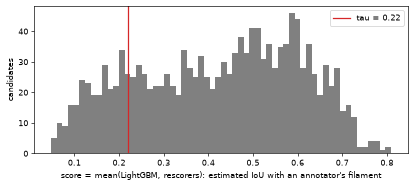

In [9]:
import pickle
from filseg import assemble
tag, rs = cfg["tag"], cfg["rescorer"]
if not TRAIN_FROM_SCRATCH:
    pipeline.run(cfg, "test", gpus=GPUS, stages=["candidates", "crops", "refiner", "rescorer"])
C = pickle.load(open(os.path.join(P.cands, f"{tag}_test.pkl"), "rb"))
d = assemble.scores(tag, "test", rescore=rs["combine"], w_cnn=rs["w_cnn"])
n_all = sum(len(v) for v in C.values())
n03 = sum(abs(c["t"] - 0.3) < 1e-6 for v in C.values() for c in v)
print(f"{n_all} candidates at thresholds {cfg['thresholds']}; {n03} at level 0.3; "
      f"{len(d['qhat'])} kept by the LightGBM scorer for refining and rescoring; "
      f"{int((d['qhat'] > cfg['tau']).sum())} with final score > tau = {cfg['tau']}")
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(d["qhat"], bins=60, color="0.5")
ax.axvline(cfg["tau"], color="C3", label=f"tau = {cfg['tau']}")
ax.set_xlabel("score = mean(LightGBM, rescorers): estimated IoU with an annotator's filament"); ax.set_ylabel("candidates")
ax.legend(); plt.tight_layout(); plt.show()

**3c. Selection and assembly** (`filseg/assemble.py`). Candidates with score > tau are pasted in decreasing score
order: the refined crop is warped back to the frame, thresholded at 0.5 and restricted to pixels that no
higher-scored filament has claimed, so the masks of a frame never overlap.

In [10]:
from filseg import submission, compare
if not TRAIN_FROM_SCRATCH:
    pipeline.run(cfg, "test", out=OUT, gpus=GPUS, stages=["assemble"])
    print(f"inference: {time.time() - t_inf:.0f} s")
rows = submission.read_csv(OUT)
submission.validate(rows, set(list_stems(P.images)))
frames = submission.by_frame(rows)
print(f"{OUT}: {len(rows)} filaments on {len(frames)} of {len(list_stems(P.images))} frames (valid, pixel-disjoint)")
if SUBMITTED and os.path.exists(SUBMITTED):
    compare.compare_csv(OUT, SUBMITTED)
if os.path.exists(os.path.join(P.work, "timings.jsonl")):
    for line in open(os.path.join(P.work, "timings.jsonl")):
        r = json.loads(line)
        if r["config"] == PICK and r["split"] == "test":
            print(f"  {r['stage']:15s} {r['seconds']:8.1f} s")

wrote submission_s15.csv: 1157 filaments on 179 frames


[s15 test] assemble: 6s


inference: 1267 s


submission_s15.csv: 1157 filaments on 179 of 180 frames (valid, pixel-disjoint)
rows_a                 1157
rows_b                 1157
frames                 179
identical_frames       74
identical_filaments    986
matched                1157
unmatched_a            0
unmatched_b            0
mean_iou_matched       0.9997955648319049
min_iou_matched        0.9525347110106555
pq_a_vs_b              0.9997955648319051
byte_identical         False
  maps              1149.1 s
  candidates          45.4 s
  crops               31.8 s
  extra_channels      23.5 s
  refiner              1.9 s
  rescorer             8.7 s
  assemble             6.4 s


The stages on one test frame: the ensemble map, the level-0.3 candidates coloured by what the selection did with
them, and the final masks (refined shapes, one colour per filament).

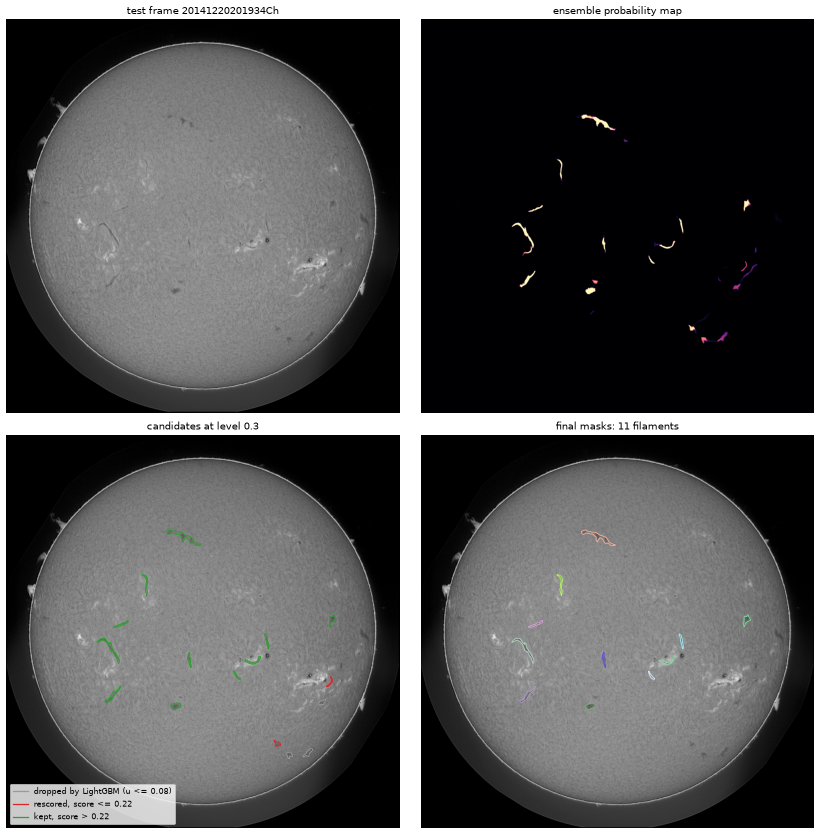

In [11]:
from filseg.candidates import ensemble_map
stems = sorted(frames, key=lambda s: -len(frames[s]))
score_by = {}
for st, j, q in zip(d["stem"], d["j"], d["qhat"]):
    score_by.setdefault(str(st), {})[int(j)] = q

def fates(s):  # (kept, dropped) level-0.3 candidates of a frame
    lev = [j for j, c in enumerate(C.get(s, [])) if abs(c["t"] - 0.3) < 1e-6]
    kept = sum(score_by.get(s, {}).get(j, -1) > cfg["tau"] for j in lev)
    return kept, len(lev) - kept

s = max(frames, key=lambda x: min(fates(x)))  # a frame with many kept and many dropped candidates
im = load_img(s, test=True)
pmap = ensemble_map(s, cfg["ensemble"], "test")
score = score_by.get(s, {})
fig, ax = plt.subplots(2, 2, figsize=(14, 14))
ax[0, 0].imshow(im, cmap="gray", vmin=0, vmax=255); ax[0, 0].set_title(f"test frame {s}")
ax[0, 1].imshow(pmap, cmap="magma", vmin=0, vmax=255); ax[0, 1].set_title("ensemble probability map")
ax[1, 0].imshow(im, cmap="gray", vmin=0, vmax=255)
fate = {"dropped by LightGBM (u <= 0.08)": "0.6", f"rescored, score <= {cfg['tau']}": "C3", f"kept, score > {cfg['tau']}": "C2"}
for j, c in enumerate(C.get(s, [])):
    if abs(c["t"] - 0.3) > 1e-6:
        continue
    col = "0.6" if j not in score else ("C2" if score[j] > cfg["tau"] else "C3")
    ax[1, 0].contour(mu.decode(c["rle"]), levels=[0.5], colors=[col], linewidths=1.0)
ax[1, 0].legend(handles=[plt.Line2D([], [], color=c, label=k) for k, c in fate.items()], loc="lower left", fontsize=9)
ax[1, 0].set_title("candidates at level 0.3")
ax[1, 1].imshow(im, cmap="gray", vmin=0, vmax=255)
rng = np.random.RandomState(0)
for r in frames[s]:
    ax[1, 1].contour(mu.decode(r), levels=[0.5], colors=[rng.uniform(0.3, 1, 3)], linewidths=1.0)
ax[1, 1].set_title(f"final masks: {len(frames[s])} filaments")
for a in ax.ravel():
    a.axis("off")
plt.tight_layout(); plt.show()

The refiner on the kept candidates of that frame with the highest scores: crop of the frame, ensemble map, candidate
mask (refiner input) and the refined mask (output, contour at 0.5).

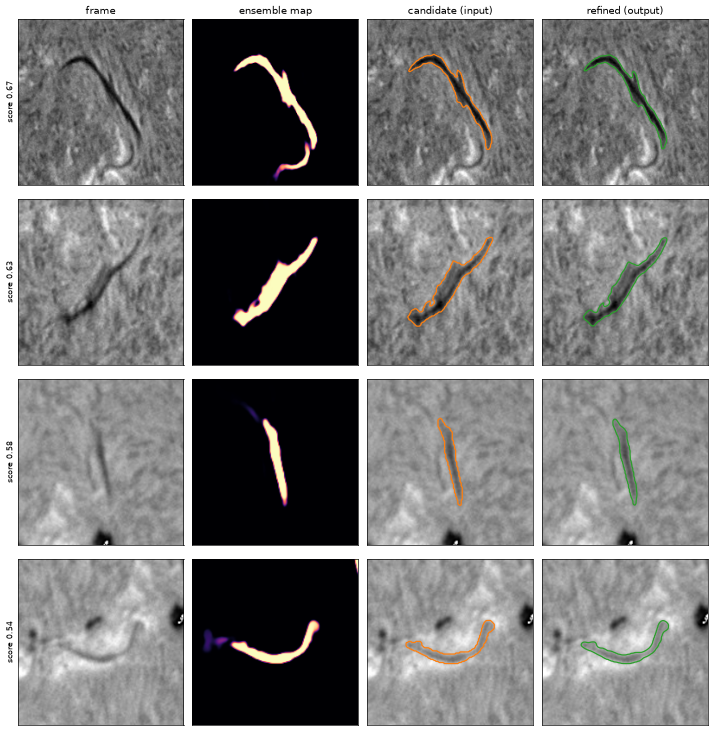

In [12]:
z = np.load(os.path.join(P.refine, f"{tag}_test.npz"))
pred = np.load(os.path.join(P.refine, f"{tag}_pred_test.npz"))["pred"]
idx = [i for i in np.argsort(-d["qhat"]) if d["stem"][i] == s][:4]
X = z["X"][idx]
fig, ax = plt.subplots(len(idx), 4, figsize=(12, 3.1 * len(idx)))
for r, i in enumerate(idx):
    ax[r, 0].imshow(X[r, 0], cmap="gray"); ax[r, 1].imshow(X[r, 1], cmap="magma", vmin=0, vmax=255)
    ax[r, 2].imshow(X[r, 0], cmap="gray"); ax[r, 2].contour(X[r, 2], levels=[127], colors=["C1"])
    ax[r, 3].imshow(X[r, 0], cmap="gray"); ax[r, 3].contour(pred[i], levels=[127], colors=["C2"])
    ax[r, 0].set_ylabel(f"score {d['qhat'][i]:.2f}")
for c, t in enumerate(["frame", "ensemble map", "candidate (input)", "refined (output)"]):
    ax[0, c].set_title(t)
for a in ax.ravel():
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()
del z, X

## 4. Evaluation

The test labels are hidden, so the pipeline is evaluated by 5-fold cross-validation on the 707 labelled training
frames: every frame is predicted by models that did not see it (dense fold models, and cross-fitted scorer, refiner
and rescorers). The OOF predictions come from

* `final/oof_<pick>.csv`: the OOF predictions of our development run, made with this code (default);
* `RECOMPUTE_OOF = True`: recomputed here from the released weights (fold models on their held-out folds, scorer refit,
  rescorer pool rebuilt and fold rescorers retrained; README, "Reproduce the cross-validation score");
* `TRAIN_FROM_SCRATCH = True`: written by the last stage of the training script.

`filseg/evaluate.py` follows the host's self-evaluation notebook: pooled PQ over every annotator record, IoU and Dice
of the overlapping (annotator filament, prediction) pairs, and the one-to-many / many-to-one matching counts.

In [13]:
from filseg.metric import image_counts, pq, summary
if TRAIN_FROM_SCRATCH:
    oof_csv = os.path.join(P.work, f"oof_{PICK}.csv")
elif RECOMPUTE_OOF:
    pipeline.run(cfg, "oof", gpus=GPUS)
    oof_csv = os.path.join(P.work, f"oof_{PICK}.csv")
else:
    oof_csv = f"final/oof_{PICK}.csv"
eval_dir = os.path.join(P.work, "eval")
run([sys.executable, "-m", "filseg.evaluate", "--pred", oof_csv, "--out_dir", eval_dir, "--name", PICK])

oof = submission.by_frame(submission.read_csv(oof_csv))
per_frame = {s: image_counts(gt[s], oof.get(s, [])) for s in meta["stems"]}
for k in range(5):
    print(f"fold {k}: {summary(sum(c for s, c in per_frame.items() if meta['folds'][s] == k))}")
print(f"pooled: {summary(sum(per_frame.values()))}")

{


 "PQ": 0.4678294770636718,


 "SQ": 0.6873006850536323,


 "TP": 5312,


 "FP": 2097,


 "FN": 2887,


... (4 outputs left out)

 "gt_one_to_many": 240,


 "pred_many_to_one": 176


}


fold 0: {'PQ': np.float64(0.45996018822860163), 'SQ': np.float64(0.6868926358357813), 'TP': 981, 'FP': 387, 'FN': 581}
fold 1: {'PQ': np.float64(0.46568699116200946), 'SQ': np.float64(0.6837811099114471), 'TP': 1184, 'FP': 467, 'FN': 642}
fold 2: {'PQ': np.float64(0.47409643982104693), 'SQ': np.float64(0.6875953520366168), 'TP': 1067, 'FP': 436, 'FN': 525}
fold 3: {'PQ': np.float64(0.49043974509050003), 'SQ': np.float64(0.6954100560130477), 'TP': 1054, 'FP': 381, 'FN': 500}
fold 4: {'PQ': np.float64(0.4497120881963539), 'SQ': np.float64(0.6831152918655141), 'TP': 1026, 'FP': 426, 'FN': 639}
pooled: {'PQ': np.float64(0.46782947706367173), 'SQ': np.float64(0.6873006850536322), 'TP': 5312, 'FP': 2097, 'FN': 2887}


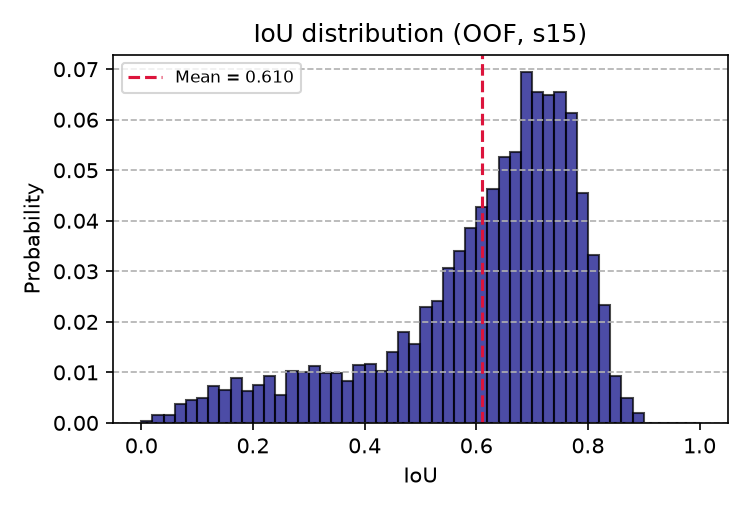

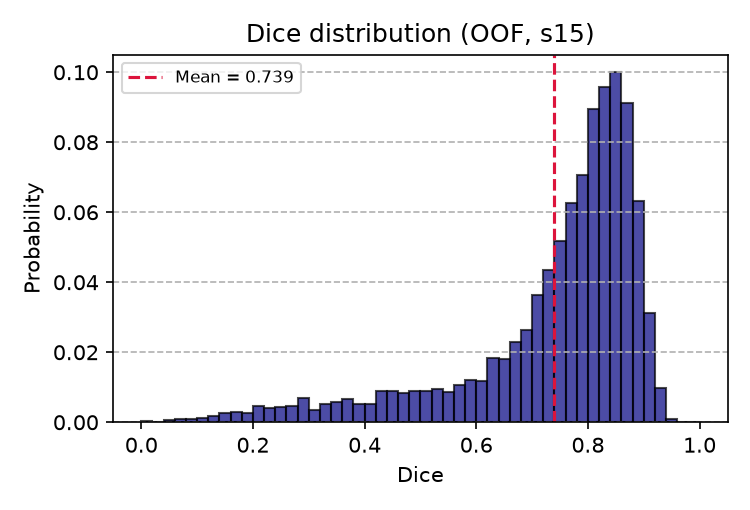

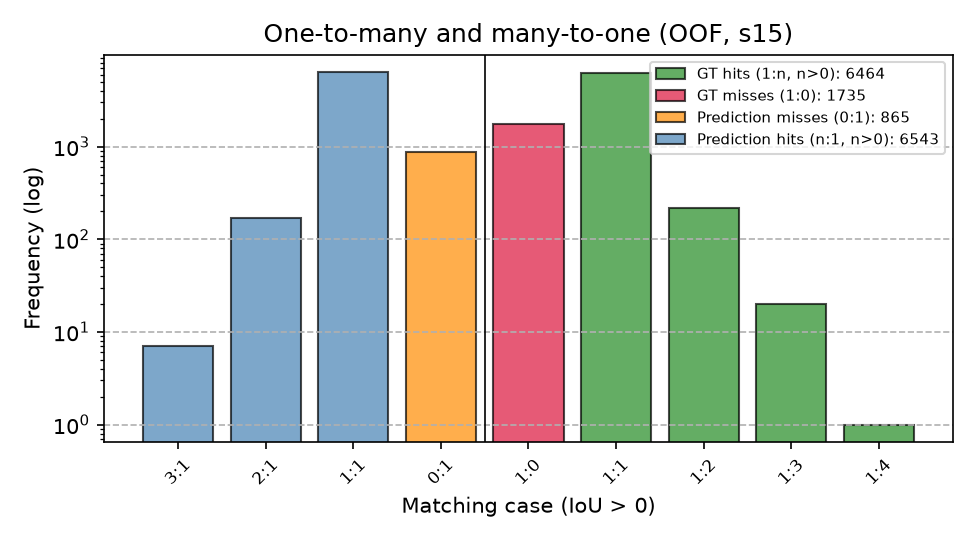

In [14]:
from IPython.display import Image, display
for k in ("iou", "dice", "m2n"):
    display(Image(os.path.join(eval_dir, f"{PICK}_{k}.png"), width=560))

OOF predictions next to the annotator records on the frames with the highest and the lowest PQ (among frames with
at least 5 annotated filaments per record on average).

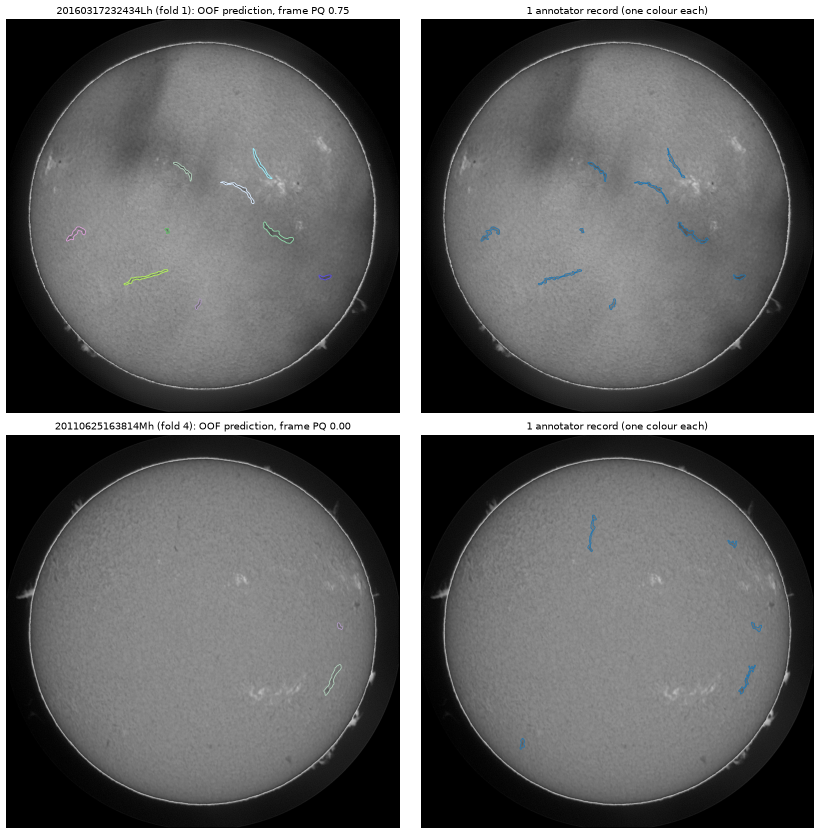

In [15]:
big = [s for s in meta["stems"] if gt[s] and sum(len(r) for r in gt[s]) / len(gt[s]) >= 5]
best, worst = max(big, key=lambda s: pq(per_frame[s])), min(big, key=lambda s: pq(per_frame[s]))
fig, ax = plt.subplots(2, 2, figsize=(14, 14))
for row, s in enumerate([best, worst]):
    im = load_img(s)
    for a in ax[row]:
        a.imshow(im, cmap="gray", vmin=0, vmax=255); a.axis("off")
    rng = np.random.RandomState(0)
    for r in oof.get(s, []):
        ax[row, 0].contour(mu.decode(r), levels=[0.5], colors=[rng.uniform(0.3, 1, 3)], linewidths=1.0)
    for i, rec in enumerate(gt[s]):
        for r in rec:
            ax[row, 1].contour(mu.decode(r), levels=[0.5], colors=[TAB[i % 10]], linewidths=0.8)
    ax[row, 0].set_title(f"{s} (fold {meta['folds'][s]}): OOF prediction, frame PQ {pq(per_frame[s]):.2f}")
    ax[row, 1].set_title(f"{records(len(gt[s]))} (one colour each)")
plt.tight_layout(); plt.show()

## 5. Predicted filaments on test frames

Each colour is one predicted filament (outline); the right panel is the ensemble probability map.

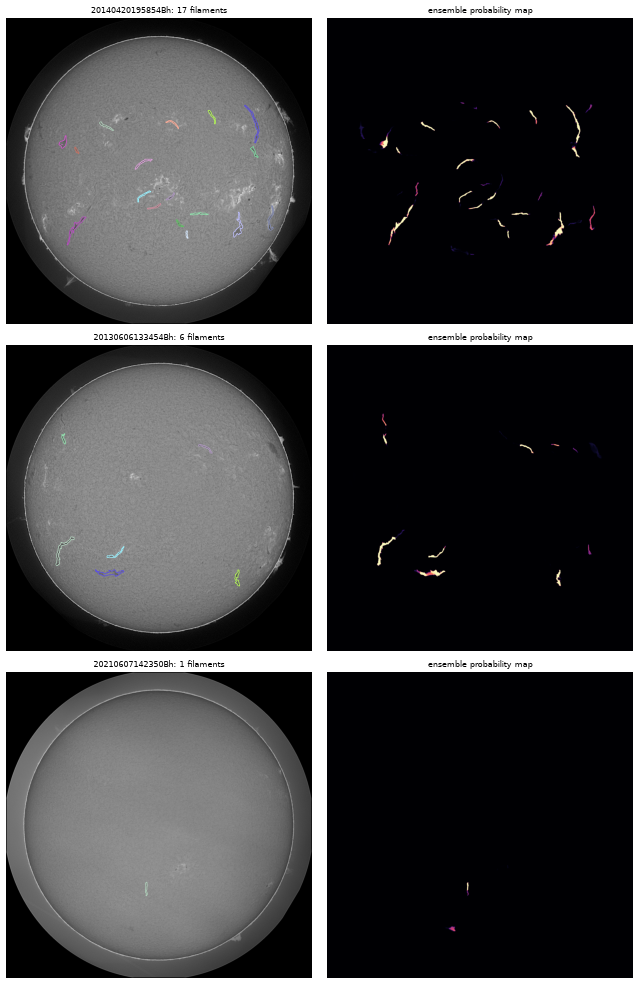

In [16]:
def show(stem, ax_img, ax_map):
    im = load_img(stem, test=True)
    ax_img.imshow(im, cmap="gray", vmin=0, vmax=255)
    rng = np.random.RandomState(0)
    for r in frames.get(stem, []):
        ax_img.contour(mu.decode(r), levels=[0.5], colors=[rng.uniform(0.3, 1, 3)], linewidths=0.9)
    ax_img.set_title(f"{stem}: {len(frames.get(stem, []))} filaments", fontsize=9)
    ax_map.imshow(ensemble_map(stem, cfg["ensemble"], "test"), cmap="magma", vmin=0, vmax=255)
    ax_map.set_title("ensemble probability map", fontsize=9)
    for a in (ax_img, ax_map):
        a.axis("off")

pick = [stems[0], stems[len(stems) // 2], stems[-1]]
fig, axes = plt.subplots(len(pick), 2, figsize=(11, 5.5 * len(pick)))
for s, (a, b) in zip(pick, axes):
    show(s, a, b)
plt.tight_layout(); plt.show()

Zoom on the frame with the most filaments:

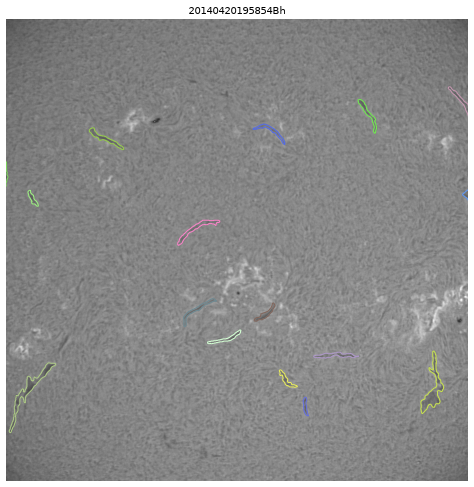

In [17]:
s = stems[0]
im = load_img(s, test=True)
fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(im[400:1650, 400:1650], cmap="gray", vmin=0, vmax=255, extent=(400, 1650, 1650, 400))
rng = np.random.RandomState(1)
for r in frames[s]:
    ax.contour(np.arange(2048), np.arange(2048), mu.decode(r), levels=[0.5], colors=[rng.uniform(0.3, 1, 3)], linewidths=1.2)
ax.set_xlim(400, 1650); ax.set_ylim(1650, 400); ax.axis("off"); ax.set_title(s)
plt.show()